# House Prices — Cấu hình A
**Ngày** 13/11/2026  
**Người thực hiện** Nguyễn Hoàng Phúc

So sánh ba mô hình trên cùng 5 fold xáo trộn với seed 42. Mục tiêu là log tự nhiên của SalePrice. RMSE log càng thấp càng tốt. Bộ tiền xử lý từ src/prepare_data.py được fit riêng trong từng fold trên dữ liệu gốc.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline

project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/models.py").is_file())
sys.path.insert(0, str(project))
from src.models import make_dummy, make_ridge, make_random_forest
from src.prepare_data import DATA_DIR, extract_features, make_preprocessor

train = pd.read_csv(DATA_DIR / "raw/train.csv")
X = extract_features(train)
assert np.isfinite(train.SalePrice).all() and train.SalePrice.gt(0).all()
y = np.log(train.SalePrice)

In [2]:
models = [
    ("DummyRegressor", make_dummy(strategy="mean"), ["strategy"]),
    ("Ridge", make_ridge(alpha=1.0), ["alpha", "solver"]),
    ("Random Forest", make_random_forest(n_estimators=200, min_samples_leaf=2, random_state=42),
     ["n_estimators", "min_samples_leaf", "random_state", "max_depth", "n_jobs"]),
]
cv = KFold(n_splits=5, shuffle=True, random_state=42)
folds = [f"Fold {i}" for i in range(1, 6)]
rows = []
for name, model, keys in models:
    params = model.get_params()
    config = ", ".join(f"{key}={params[key]}" for key in keys)
    pipeline = make_pipeline(make_preprocessor(X), model)
    scores = -cross_val_score(pipeline, X, y, cv=cv,
                              scoring="neg_root_mean_squared_error", error_score="raise")
    rows.append([name, config, *scores, scores.mean(), scores.std(ddof=1)])
results = pd.DataFrame(rows, columns=["Mô hình", "Tham số", *folds, "RMSE TB", "Độ lệch chuẩn"])
results = results.sort_values("RMSE TB", ignore_index=True)
print(results.round(5).to_string(index=False))

       Mô hình                                                                          Tham số  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  RMSE TB  Độ lệch chuẩn
 Random Forest n_estimators=200, min_samples_leaf=2, random_state=42, max_depth=None, n_jobs=-1 0.14676 0.12849 0.17740 0.14892 0.12276  0.14487        0.02142
         Ridge                                                           alpha=1.0, solver=lsqr 0.13393 0.12703 0.22838 0.13340 0.11695  0.14793        0.04549
DummyRegressor                                                                    strategy=mean 0.43325 0.39584 0.37537 0.42101 0.36845  0.39878        0.02810


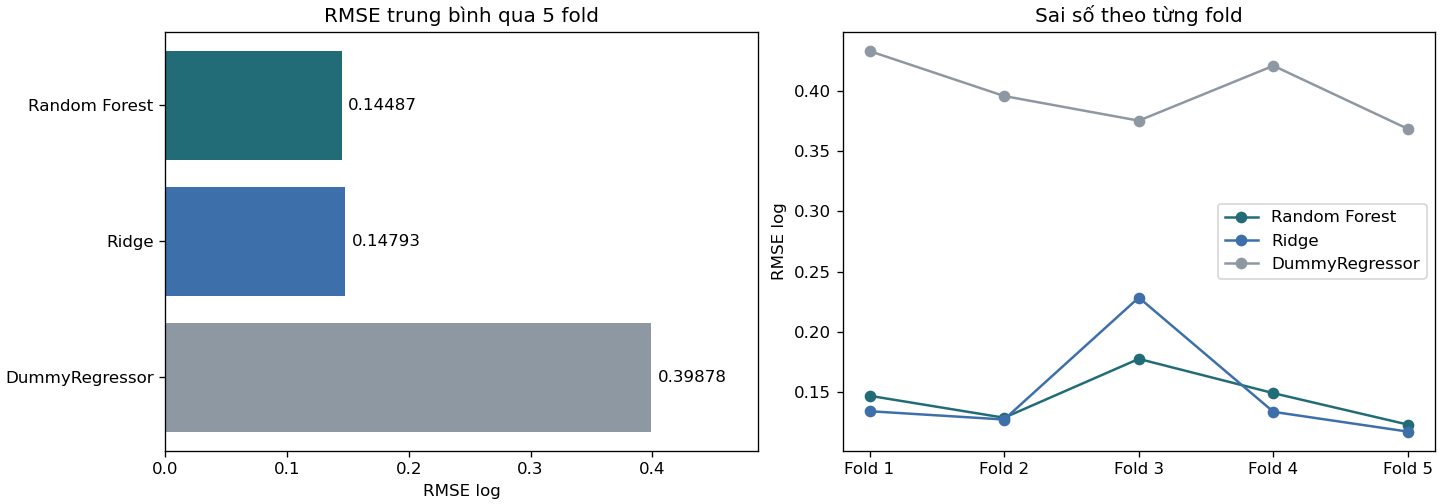

In [3]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
colors = ["#226C78", "#3D70AA", "#8E98A2"]
left.barh(results["Mô hình"], results["RMSE TB"], color=colors)
left.invert_yaxis()
left.bar_label(left.containers[0], fmt="%.5f", padding=4)
left.set(xlabel="RMSE log", title="RMSE trung bình qua 5 fold",
         xlim=(0, results["RMSE TB"].max() * 1.22))
for (_, row), color in zip(results.iterrows(), colors):
    right.plot(folds, row[folds].to_numpy(dtype=float), marker="o", color=color, label=row["Mô hình"])
right.set(ylabel="RMSE log", title="Sai số theo từng fold")
right.legend()
plt.show()

In [4]:
by_model = results.set_index("Mô hình")
best = results.iloc[0]
ridge = by_model.loc["Ridge"]
forest = by_model.loc["Random Forest"]
dummy = by_model.loc["DummyRegressor"]
reduction = (1 - best["RMSE TB"] / dummy["RMSE TB"]) * 100
ridge_wins = sum(ridge[fold] < forest[fold] for fold in folds)
comments = [
    f"{best['Mô hình']} có RMSE log trung bình thấp nhất ({best['RMSE TB']:.5f}), thấp hơn Dummy {reduction:.1f}%.",
    f"Ridge đạt {ridge['RMSE TB']:.5f} và có sai số thấp hơn Random Forest ở {ridge_wins}/5 fold.",
    f"Độ lệch chuẩn qua các fold của Random Forest là {forest['Độ lệch chuẩn']:.5f}, so với {ridge['Độ lệch chuẩn']:.5f} của Ridge.",
    "Kết quả đo trên tập train bằng cross-validation. Tập test chưa có giá bán thực để tính RMSE.",
]
for comment in comments:
    print(comment)

Random Forest có RMSE log trung bình thấp nhất (0.14487), thấp hơn Dummy 63.7%.
Ridge đạt 0.14793 và có sai số thấp hơn Random Forest ở 4/5 fold.
Độ lệch chuẩn qua các fold của Random Forest là 0.02142, so với 0.04549 của Ridge.
Kết quả đo trên tập train bằng cross-validation. Tập test chưa có giá bán thực để tính RMSE.
